In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [ ]:
df=pd.read_csv("/content/telecom_usage_mixed.csv")
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 257 entries, 0 to 256
Data columns (total 10 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   monthly_minutes      244 non-null    object 
 1   user_id              245 non-null    object 
 2   monthly_data_mb      236 non-null    float64
 3   monthly_sms          240 non-null    float64
 4   monthly_data_mb_dup  236 non-null    float64
 5   contract_months      248 non-null    float64
 6   churn_next_month     241 non-null    float64
 7   plan_type            232 non-null    object 
 8   has_family_plan      236 non-null    object 
 9   overdue_payments     242 non-null    float64
dtypes: float64(6), object(4)
memory usage: 20.2+ KB


In [ ]:
df.head()

,monthly_minutes,user_id,monthly_data_mb,monthly_sms,monthly_data_mb_dup,contract_months,churn_next_month,plan_type,has_family_plan,overdue_payments
0,1351.0,U70000,1213.0,15.0,1213.0,17.0,0.0,Basic,No,1.0
1,1041.0,U70001,1215.0,12.0,1215.0,14.0,1.0,UNLIMITED,No,2.0
2,1182.0,U70002,1546.0,199.0,1546.0,3.0,NaN,BASIC,Yes,2.0
3,1281.0,U70003,2014.0,183.0,2014.0,33.0,0.0,Basic,No,0.0
4,1482.0,U70004,6308.0,308.0,6308.0,16.0,0.0,Standard,N,1.0


original shape of the data

In [ ]:
print("Original Dataset Shape:", df.shape)

Original Dataset Shape: (257, 10)


Check missing value count per column

In [ ]:
print("Missing values per column:")
df.isnull().sum()

Missing values per column:


,0
monthly_minutes,13
user_id,12
monthly_data_mb,21
monthly_sms,17
monthly_data_mb_dup,21
contract_months,9
churn_next_month,16
plan_type,25
has_family_plan,21
overdue_payments,15


Remove exact duplicate records

In [ ]:
df=df.drop_duplicates()

Remove duplicate column

In [ ]:
df = df.drop(columns=["monthly_data_mb_dup"])

In [ ]:
df

,monthly_minutes,user_id,monthly_data_mb,monthly_sms,contract_months,churn_next_month,plan_type,has_family_plan,overdue_payments
0,1351.0,U70000,1213.0,15.0,17.0,0.0,Basic,No,1.0
1,1041.0,U70001,1215.0,12.0,14.0,1.0,UNLIMITED,No,2.0
2,1182.0,U70002,1546.0,199.0,3.0,NaN,BASIC,Yes,2.0
3,1281.0,U70003,2014.0,183.0,33.0,0.0,Basic,No,0.0
4,1482.0,U70004,6308.0,308.0,16.0,0.0,Standard,N,1.0
...,...,...,...,...,...,...,...,...,...
245,620.0,U70245,1942.0,131.0,16.0,0.0,Basc,No,1.0
246,781.0,U70246,1163.0,289.0,24.0,0.0,Unlimited,No,1.0
247,858.0,U70247,550.0,449.0,29.0,0.0,Standard,Ye,1.0
248,1200.0,U70248,1127.0,446.0,28.0,0.0,STANDARD,YES,1.0


convert monthly_minutes to numeric

In [ ]:
df['monthly_minutes'] = pd.to_numeric(df['monthly_minutes'], errors='coerce')

filling missing values in columns

In [ ]:
df["monthly_data_mb"].fillna(df["monthly_data_mb"].mean(), inplace=True)


/tmp/ipykernel_3820/1482143869.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df["monthly_data_mb"].fillna(df["monthly_data_mb"].mean(), inplace=True)


In [ ]:
df['monthly_minutes'] = df['monthly_minutes'].fillna(df['monthly_minutes'].median())
df['monthly_sms'] = df['monthly_sms'].fillna(df['monthly_sms'].median())
df['contract_months'] = df['contract_months'].fillna(round(df['contract_months'].mean()))
df['overdue_payments'] = df['overdue_payments'].fillna(df['overdue_payments'].mode()[0])

Convert to string, strip whitespace, and convert to lowercase

In [ ]:
df['plan_type'] = df['plan_type'].astype(str).str.strip().str.lower()
df['has_family_plan'] = df['has_family_plan'].astype(str).str.strip().str.lower()
df

,monthly_minutes,user_id,monthly_data_mb,monthly_sms,contract_months,churn_next_month,plan_type,has_family_plan,overdue_payments
0,1351.0,U70000,1213.0,15.0,17.0,0.0,basic,no,1.0
1,1041.0,U70001,1215.0,12.0,14.0,1.0,unlimited,no,2.0
2,1182.0,U70002,1546.0,199.0,3.0,NaN,basic,yes,2.0
3,1281.0,U70003,2014.0,183.0,33.0,0.0,basic,no,0.0
4,1482.0,U70004,6308.0,308.0,16.0,0.0,standard,n,1.0
...,...,...,...,...,...,...,...,...,...
245,620.0,U70245,1942.0,131.0,16.0,0.0,basc,no,1.0
246,781.0,U70246,1163.0,289.0,24.0,0.0,unlimited,no,1.0
247,858.0,U70247,550.0,449.0,29.0,0.0,standard,ye,1.0
248,1200.0,U70248,1127.0,446.0,28.0,0.0,standard,yes,1.0


 Fill missing categorical values with the mode

In [ ]:
df['plan_type'] = df['plan_type'].fillna(df['plan_type'].mode()[0])
df['has_family_plan'] = df['has_family_plan'].fillna(df['has_family_plan'].mode()[0])

Fix typos and standardize values

In [ ]:
df['has_family_plan'] = df['has_family_plan'].replace({
    'y': 'yes', 'ye': 'yes', 'n': 'no'
})
df['plan_type'] = df['plan_type'].replace({'basc': 'basic'})

clean and fix all typos

In [ ]:

df['has_family_plan'] = df['has_family_plan'].replace({
    'y': 'yes', 'ye': 'yes', 'ys': 'yes',
    'n': 'no', 'o': 'no'
})


df['plan_type'] = df['plan_type'].replace({
    'baic': 'basic', 'basi': 'basic',
    'sandard': 'standard',
    'unimited': 'unlimited', 'unliited': 'unlimited',
    'unlimitd': 'unlimited', 'unlmited': 'unlimited'
})
df['has_family_plan'] = df['has_family_plan'].replace({
    'nan': 'no'
})

/tmp/ipykernel_3820/2573601507.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['has_family_plan'] = df['has_family_plan'].replace({
/tmp/ipykernel_3820/2573601507.py:7: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['plan_type'] = df['plan_type'].replace({
/tmp/ipykernel_3820/2573601507.py:13: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata

Drop rows where target variable is missing


In [ ]:
df = df.dropna(subset=['churn_next_month'])

Convert categorical features into binary/dummy variables

In [ ]:

df_encoded = pd.get_dummies(df, columns=['plan_type', 'has_family_plan'], drop_first=True)

In [ ]:
if 'user_id' in df_encoded.columns:
    df_encoded = df_encoded.drop(columns=['user_id'])

Feature Scaling (Standardization)

In [ ]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
num_cols = ['monthly_minutes', 'monthly_data_mb', 'monthly_sms', 'contract_months', 'overdue_payments']

df_encoded[num_cols] = scaler.fit_transform(df_encoded[num_cols])

print("Final Dataset Shape:", df_encoded.shape)
df_encoded.head()

Final Dataset Shape: (235, 11)


,monthly_minutes,monthly_data_mb,monthly_sms,contract_months,churn_next_month,overdue_payments,plan_type_basic,plan_type_standard,plan_type_unlimited,has_family_plan_no,has_family_plan_yes
0,-0.016784,-0.360510,-1.782271,-0.050144,0.0,-0.352785,True,False,False,True,False
1,-0.092286,-0.359549,-1.803275,-0.352294,1.0,0.600140,False,False,True,True,False
3,-0.033833,0.024399,-0.606067,1.561323,0.0,-1.305711,True,False,False,True,False
4,0.015121,2.087820,0.269085,-0.150861,0.0,-0.352785,False,True,False,True,False
5,0.002456,0.071491,0.234079,-1.158027,0.0,1.553066,True,False,False,False,False


In [ ]:
df.shape

(235, 9)

In [ ]:

df_encoded.to_csv('telecom_churn_preprocessed.csv', index=False)

Outliers Handling

In [ ]:

num_cols = ['monthly_minutes', 'monthly_data_mb', 'monthly_sms', 'contract_months']

for col in num_cols:
    Q1 = df_encoded[col].quantile(0.25)
    Q3 = df_encoded[col].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    df_encoded[col] = np.where(df_encoded[col] < lower_bound, lower_bound, df_encoded[col])
    df_encoded[col] = np.where(df_encoded[col] > upper_bound, upper_bound, df_encoded[col])


Visualization

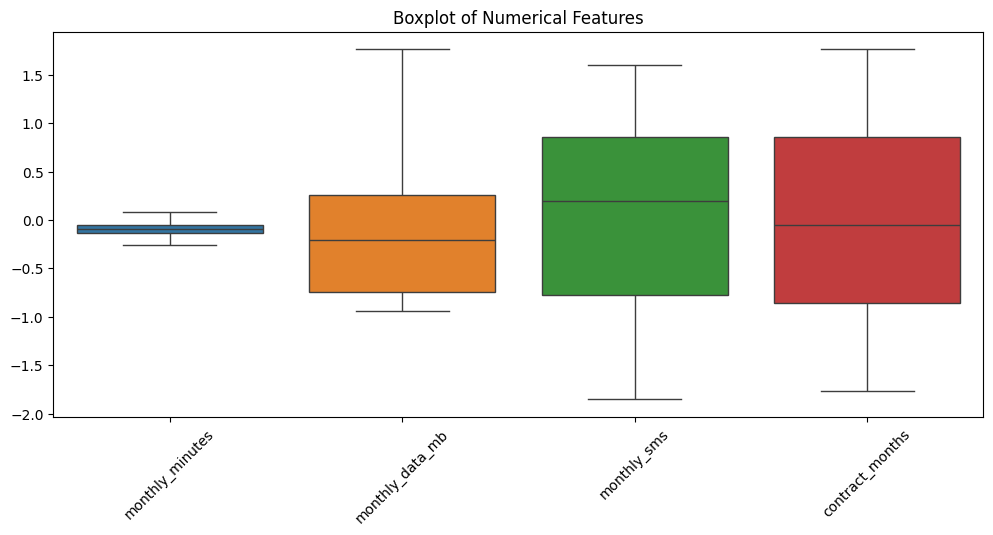

In [ ]:
plt.figure(figsize=(12, 5))
sns.boxplot(data=df_encoded[num_cols])
plt.title("Boxplot of Numerical Features")
plt.xticks(rotation=45)
plt.show()

Univariate analysis

Bar Chart

/tmp/ipykernel_3820/3631827680.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=plan_counts.index, y=plan_counts.values, palette='Blues_d')


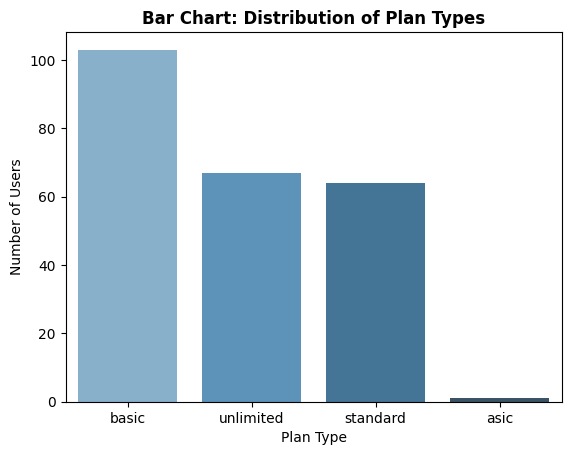

In [ ]:

plan_counts = df['plan_type'].value_counts()
sns.barplot(x=plan_counts.index, y=plan_counts.values, palette='Blues_d')
plt.title('Bar Chart: Distribution of Plan Types', fontweight='bold')
plt.xlabel('Plan Type')
plt.ylabel('Number of Users')
plt.show()

Count plot

/tmp/ipykernel_3820/3914351004.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='plan_type', data=df, palette='viridis')


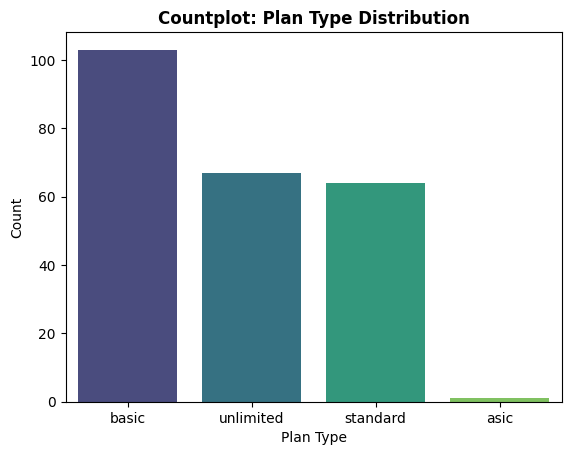

In [ ]:

sns.countplot(x='plan_type', data=df, palette='viridis')
plt.title('Countplot: Plan Type Distribution', fontsize=12, fontweight='bold')
plt.xlabel('Plan Type')
plt.ylabel('Count')
plt.show()

pie chart

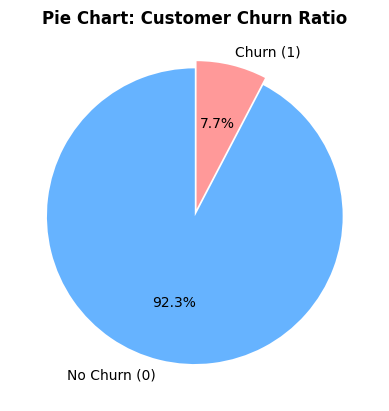

In [ ]:

churn_counts = df['churn_next_month'].value_counts()
plt.pie(churn_counts, labels=['No Churn (0)', 'Churn (1)'], autopct='%1.1f%%', colors=['#66b3ff','#ff9999'], startangle=90, explode=(0, 0.05))
plt.title('Pie Chart: Customer Churn Ratio', fontsize=12, fontweight='bold')
plt.show()

Histogram

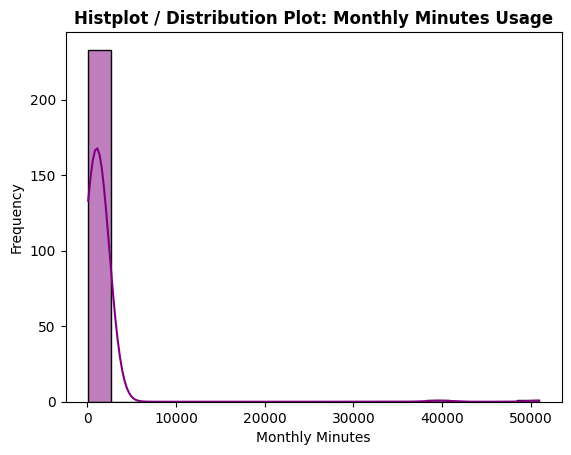

In [ ]:

sns.histplot(df['monthly_minutes'], kde=True, color='purple', bins=20)
plt.title('Histplot / Distribution Plot: Monthly Minutes Usage', fontsize=12, fontweight='bold')
plt.xlabel('Monthly Minutes')
plt.ylabel('Frequency')
plt.show()

Violin plot

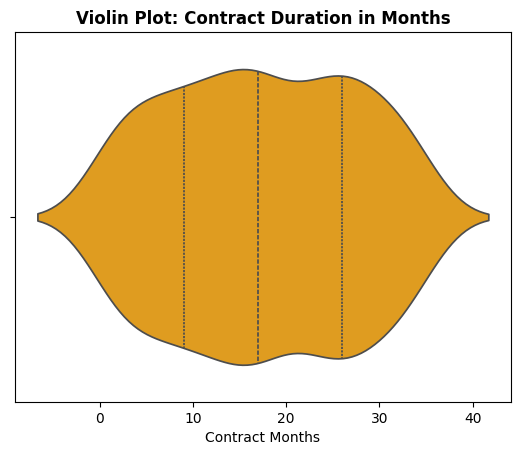

In [ ]:

sns.violinplot(x=df['contract_months'], color='orange', inner='quartile')
plt.title('Violin Plot: Contract Duration in Months', fontsize=12, fontweight='bold')
plt.xlabel('Contract Months')
plt.show()

Bivariate analysis

Scatter plot

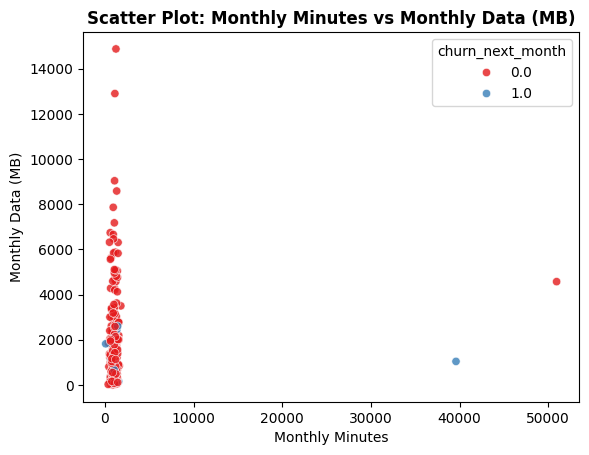

In [ ]:

sns.scatterplot(x='monthly_minutes', y='monthly_data_mb', hue='churn_next_month', data=df, palette='Set1', alpha=0.8)
plt.title('Scatter Plot: Monthly Minutes vs Monthly Data (MB)', fontsize=12, fontweight='bold')
plt.xlabel('Monthly Minutes')
plt.ylabel('Monthly Data (MB)')
plt.show()

Count plot

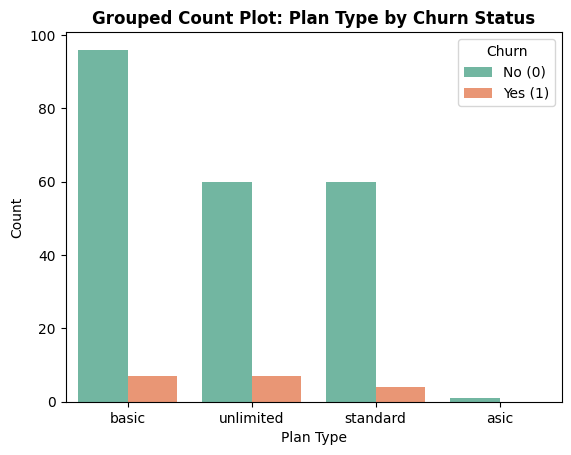

In [ ]:
sns.countplot(x='plan_type', hue='churn_next_month', data=df, palette='Set2')
plt.title('Grouped Count Plot: Plan Type by Churn Status', fontsize=12, fontweight='bold')
plt.xlabel('Plan Type')
plt.ylabel('Count')
plt.legend(title='Churn', labels=['No (0)', 'Yes (1)'])
plt.show()

Stacked Bar Chart

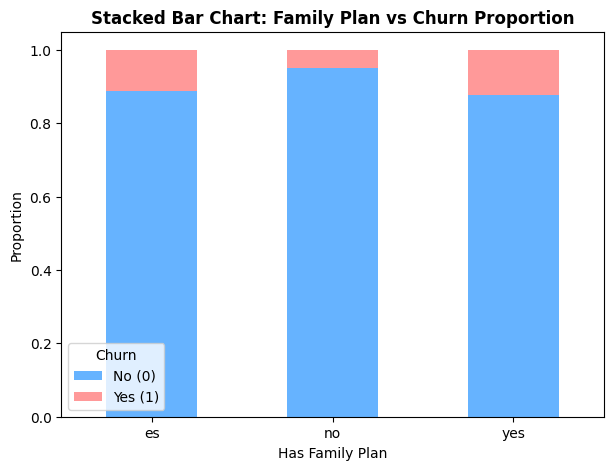

In [ ]:
crosstab_prop = pd.crosstab(df['has_family_plan'], df['churn_next_month'], normalize='index')
crosstab_prop.plot(kind='bar', stacked=True, color=['#66b3ff', '#ff9999'], figsize=(7, 5))
plt.title('Stacked Bar Chart: Family Plan vs Churn Proportion', fontsize=12, fontweight='bold')
plt.xlabel('Has Family Plan')
plt.ylabel('Proportion')
plt.legend(title='Churn', labels=['No (0)', 'Yes (1)'])
plt.xticks(rotation=0)
plt.show()

Box plot(Continous vs categorical variable)

/tmp/ipykernel_3820/2091941691.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='churn_next_month', y='contract_months', data=df, palette='Pastel1')


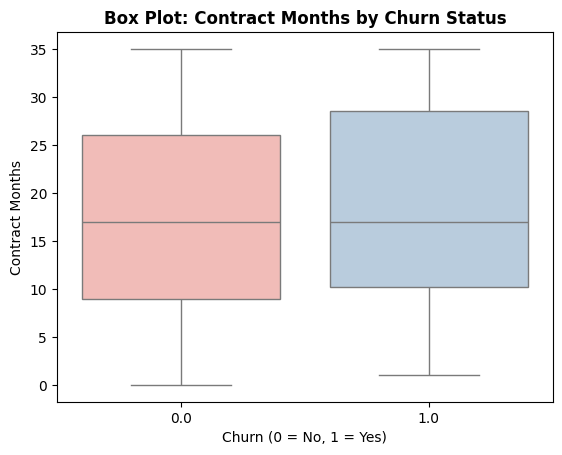

In [ ]:
sns.boxplot(x='churn_next_month', y='contract_months', data=df, palette='Pastel1')
plt.title('Box Plot: Contract Months by Churn Status', fontsize=12, fontweight='bold')
plt.xlabel('Churn (0 = No, 1 = Yes)')
plt.ylabel('Contract Months')
plt.show()

Multivariate analysis

HeatMap

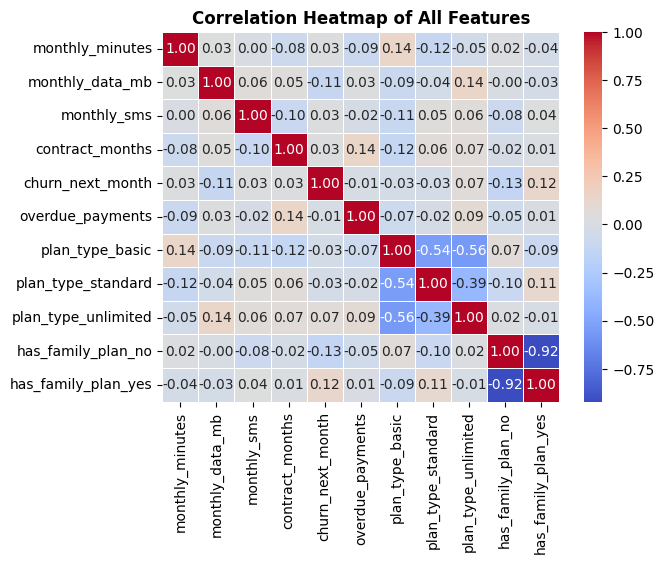

In [ ]:
correlation_matrix = df_encoded.corr()
sns.heatmap(correlation_matrix, annot=True, fmt=".2f", cmap='coolwarm', linewidths=0.5, cbar=True)
plt.title('Correlation Heatmap of All Features', fontsize=12, fontweight='bold')
plt.show()

Pair Plot

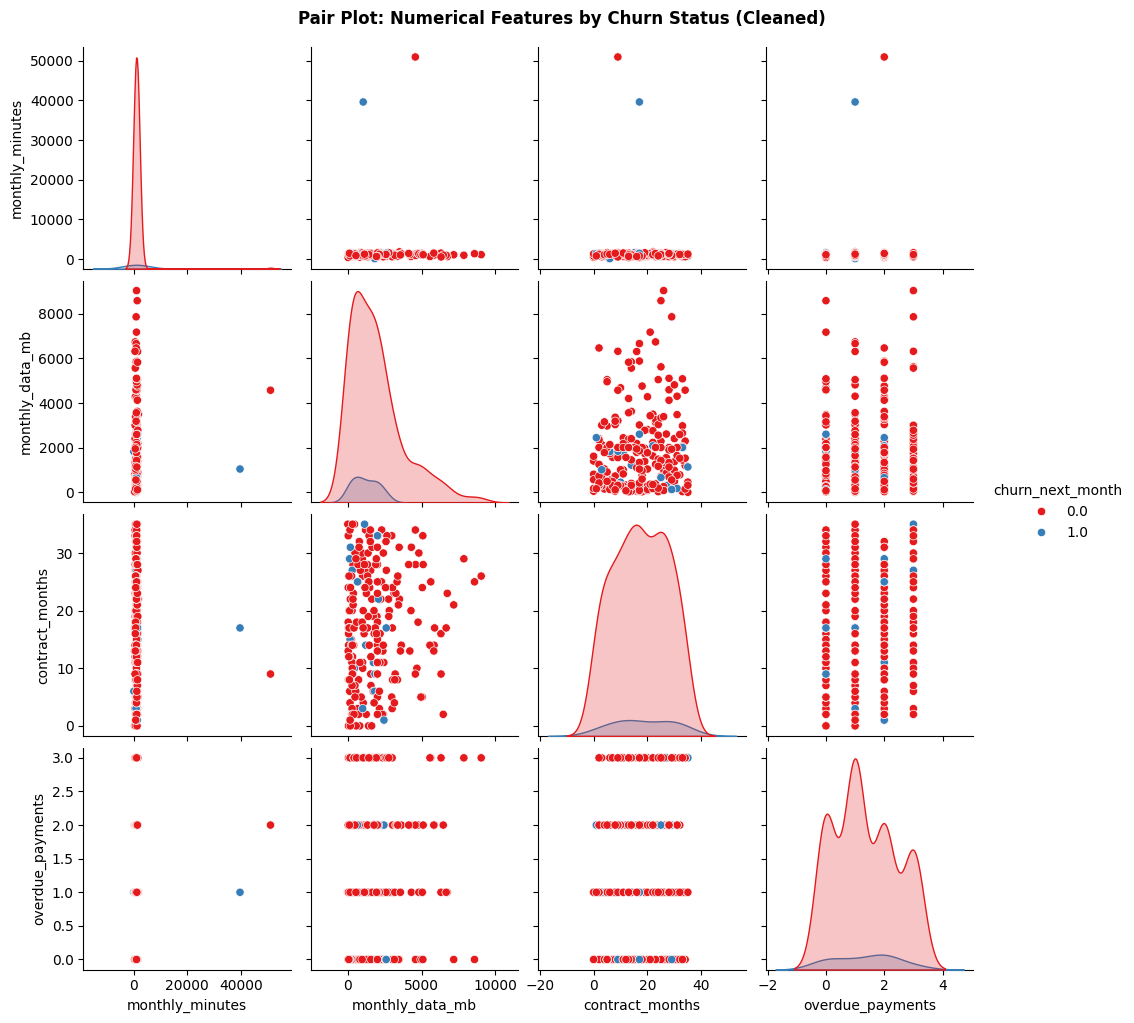

In [ ]:
num_vars = ['monthly_minutes', 'monthly_data_mb', 'contract_months', 'overdue_payments', 'churn_next_month']
sns.pairplot(df[num_vars], hue='churn_next_month', palette='Set1', diag_kind='kde', corner=True)
plt.suptitle('Pair Plot: Numerical Features by Churn Status', y=1.02, fontsize=12, fontweight='bold')
plt.show()